# NHSN Dialysis Event Module: Synthetic Data Generator + Data Quality Validation Pipeline

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/nhsn-dialysis-analytics/blob/main/notebooks/00_01_synthetic_data_and_data_quality.ipynb)

**Portfolio project 1 of 5** | Role focus: Data Analyst I, NHSN Dialysis Event prevention and surveillance support

---
## Data statement (read first)
**No PHI and no real NHSN data are used anywhere in this notebook.** All facilities, patients, events, and errors are
simulated. Event rates are *illustrative* and chosen only to produce realistic-looking sparse count data. The validation
rules below are modeled on the *kinds* of checks surveillance analysts run (reporting-month logic, denominator
consistency, 21-day duplicate logic, timeliness). **Before any real use, rules must be reconciled with the current NHSN
Dialysis Event Protocol and the Patient Safety Component manual.** Terminology note: NHSN dialysis "events" are
surveillance events (positive blood culture, IV antimicrobial start, pus/redness/swelling at the access site), not
necessarily confirmed infections.

## What this notebook does
| Step | Output | Job-description duty it maps to |
|---|---|---|
| 1. Synthetic generator | Facilities, monthly denominators (patient-months by access type), event line list | Data management |
| 2. Error injection with ground truth | Known planted problems so detection can be *measured* | Data validation projects |
| 3. Rule-based validation | 10 documented rules, per-rule performance | Data quality, form/instruction recommendations |
| 4. Statistical anomaly detection | Robust z-scores, Poisson checks, funnel plot with overdispersion | Quality assessment analyses |
| 5. ML anomaly detection | Denoising autoencoder (PyTorch) vs Isolation Forest vs rules | Advanced analytics |
| 6. Facility scorecard | 0-100 data quality score and outreach tier | User outreach, reports |
| 7. Modification tracking log + form edits | Prioritized change log | System modifications, form updates |
| 8. Exports | CSV, Excel workbook, data dictionary | Reports, government-style documentation |

Everything runs top to bottom in about 2-4 minutes on a free Colab CPU runtime. Random seeds are fixed.

## 0. Setup

In [1]:
import sys, subprocess, importlib, warnings, os, shutil
warnings.filterwarnings("ignore")

def _ensure(pip_name, import_name=None):
    """Install a package only if it is missing (Colab already has most of these)."""
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for pip_name, imp in [("numpy", None), ("pandas", None), ("scipy", None), ("matplotlib", None),
                      ("scikit-learn", "sklearn"), ("openpyxl", None), ("torch", None)]:
    _ensure(pip_name, imp)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import torch
import torch.nn as nn
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
print("pandas", pd.__version__, "| torch", torch.__version__, "| seed", SEED)

pandas 2.2.3 | torch 2.6.0+cpu | seed 42


## 1. Configuration
One place for every assumption, so changes are traceable (this mirrors how a protocol-style change log works).

In [2]:
N_FACILITIES = 160
MONTHS = pd.period_range("2023-01", "2024-12", freq="M")      # 24 reporting months
ACCESS = ["AVF", "AVG", "CVC_tunneled", "CVC_nontunneled", "Other"]
EVENT_TYPES = ["positive_blood_culture", "iv_antimicrobial_start", "pus_redness_swelling"]

# Illustrative baseline rates per 100 patient-months, by access type (columns follow EVENT_TYPES order).
BASE_RATE = {
    "AVF":             [0.15, 0.45, 0.10],
    "AVG":             [0.35, 0.90, 0.25],
    "CVC_tunneled":    [1.10, 2.00, 0.40],
    "CVC_nontunneled": [2.50, 3.50, 0.80],
    "Other":           [0.30, 0.80, 0.20],
}

LATE_DAYS = 30           # submission later than this many days after month end counts as late
DUP_WINDOW_DAYS = 21     # same patient + same event type within this window = duplicate (illustrative rule)
MIN_PLAUSIBLE_YEAR = 2015

# Probability each record is hit by an injected error (facility-month level, then event level).
ERR_RATES = dict(
    missing=0.020, patient_typo=0.015, sum_mismatch=0.020, zero_access=0.030, late=0.030, inflation=0.025,
    duplicate=0.020, date_outside=0.015, date_implausible=0.007, access_swapped=0.015,
)
print(f"{N_FACILITIES} facilities x {len(MONTHS)} months = {N_FACILITIES*len(MONTHS):,} facility-months")

160 facilities x 24 months = 3,840 facility-months


## 2. Synthetic NHSN-like data generator
Design choices:
- **Facilities** vary by size, state/network, ownership, urban/rural, and access mix. Each has a latent risk effect
  (log-normal) so rates are overdispersed, as in real surveillance data.
- **Denominator** = patients under care by access type each month (the patient-month denominator).
- **Events** are Poisson counts per access type and event type, multiplied by a facility effect and a monthly gamma
  shock (extra-Poisson variation).
- A simulated **prevention collaborative** (40% of facilities) lowers CVC-related rates from 2024-01. It is not used
  in this notebook but is built in now so the trend/intervention notebook can reuse the same dataset.

In [3]:
def make_facilities(n, rng):
    states = ["FL", "GA", "TX", "CA", "NY", "OH", "PA", "IL", "NC", "MI"]
    state_network = {s: f"NW-{(i % 6) + 1:02d}" for i, s in enumerate(states)}   # synthetic network codes
    fac = pd.DataFrame({"facility_id": [f"FAC{i+1:04d}" for i in range(n)]})
    fac["state"] = rng.choice(states, n)
    fac["network"] = fac["state"].map(state_network)
    fac["ownership"] = rng.choice(["Large_chain", "Nonprofit", "Independent"], n, p=[0.60, 0.25, 0.15])
    fac["urban_rural"] = rng.choice(["Urban", "Rural"], n, p=[0.78, 0.22])
    size = rng.lognormal(np.log(65), 0.45, n) * np.where(fac["urban_rural"] == "Rural", 0.7, 1.0)
    fac["mean_census"] = np.clip(size, 15, 250).round().astype(int)
    base_mix = np.array([0.62, 0.13, 0.17, 0.02, 0.06])
    mix = np.vstack([rng.dirichlet(base_mix * 60) for _ in range(n)])
    for j, a in enumerate(ACCESS):
        fac[f"mix_{a}"] = mix[:, j]
    fac["log_effect"] = rng.normal(0, 0.35, n)             # latent facility risk (ground truth, never used as a feature)
    fac["in_collaborative"] = rng.random(n) < 0.40
    return fac


def make_clean_denominator(fac, months, rng):
    rows, mix_cols = [], [f"mix_{a}" for a in ACCESS]
    for f in fac.itertuples(index=False):
        mix = np.array([getattr(f, c) for c in mix_cols]); mix = mix / mix.sum()
        drift = rng.normal(0.002, 0.003)                    # slow census growth/decline
        for t, m in enumerate(months):
            start = m.to_timestamp()
            end = (m + 1).to_timestamp() - pd.Timedelta(days=1)
            total = max(8, int(round(f.mean_census * (1 + drift * t) * (1 + rng.normal(0, 0.025)))))
            counts = rng.multinomial(total, mix)
            delay = int(np.clip(rng.gamma(2.0, 5.0), 3, 28))   # typical on-time submission
            rows.append({"facility_id": f.facility_id, "month": start,
                         "report_date": end + pd.Timedelta(days=delay), "patients_total": total,
                         **{f"n_{a}": int(c) for a, c in zip(ACCESS, counts)}})
    return pd.DataFrame(rows)


def make_clean_events(fac, den, rng):
    info = fac.set_index("facility_id")[["log_effect", "in_collaborative", "mean_census"]].to_dict("index")
    collab_start, rows = pd.Timestamp("2024-01-01"), []
    for r in den.itertuples(index=False):
        f = info[r.facility_id]
        ndays = r.month.days_in_month
        post = bool(f["in_collaborative"]) and r.month >= collab_start
        shock = rng.gamma(20, 1 / 20)                         # monthly extra-Poisson variation
        pool = int(f["mean_census"] * 1.6)
        for a in ACCESS:
            n_a = getattr(r, f"n_{a}")
            if n_a == 0:
                continue
            mult = 0.7 if (post and a.startswith("CVC")) else 1.0
            for k, et in enumerate(EVENT_TYPES):
                lam = n_a * BASE_RATE[a][k] / 100 * np.exp(f["log_effect"]) * shock * mult
                for _ in range(rng.poisson(lam)):
                    rows.append({"facility_id": r.facility_id, "month": r.month,
                                 "patient_id": f"{r.facility_id}-P{rng.integers(1, pool + 1):04d}",
                                 "event_type": et, "access_type": a,
                                 "event_date": r.month + pd.Timedelta(days=int(rng.integers(0, ndays)))})
    return pd.DataFrame(rows)


def enforce_dup_window(ev, window=DUP_WINDOW_DAYS):
    """Clean data should already obey the duplicate-event rule: drop a repeat for the same patient/type inside the window."""
    ev = ev.sort_values(["facility_id", "patient_id", "event_type", "event_date"]).reset_index(drop=True)
    keep, last_key, last_date = np.ones(len(ev), bool), None, None
    for i, (fid, pid, et, d) in enumerate(zip(ev.facility_id, ev.patient_id, ev.event_type, ev.event_date)):
        key = (fid, pid, et)
        if key == last_key and (d - last_date).days <= window:
            keep[i] = False
            continue
        last_key, last_date = key, d
    return ev[keep].reset_index(drop=True)


fac = make_facilities(N_FACILITIES, rng)
den_clean = make_clean_denominator(fac, MONTHS, rng)
ev_clean = enforce_dup_window(make_clean_events(fac, den_clean, rng))
ev_clean = ev_clean.sort_values(["facility_id", "month", "event_date"]).reset_index(drop=True)
ev_clean.insert(0, "event_id", [f"EV{i+1:06d}" for i in range(len(ev_clean))])

print(f"Clean denominator rows: {len(den_clean):,} | Clean events: {len(ev_clean):,}")
display(fac.drop(columns=[c for c in fac.columns if c.startswith('mix_')]).head())
display(den_clean.head())
display(ev_clean.head())

Clean denominator rows: 3,840 | Clean events: 3,779


,facility_id,state,network,ownership,urban_rural,mean_census,log_effect,in_collaborative
0,FAC0001,FL,NW-01,Nonprofit,Rural,55,0.078504,False
1,FAC0002,IL,NW-02,Large_chain,Rural,58,0.210336,False
2,FAC0003,PA,NW-01,Nonprofit,Urban,74,0.116386,True
3,FAC0004,NY,NW-05,Large_chain,Urban,34,-0.283309,False
4,FAC0005,NY,NW-05,Large_chain,Urban,23,0.237120,True


,facility_id,month,report_date,patients_total,n_AVF,n_AVG,n_CVC_tunneled,n_CVC_nontunneled,n_Other
0,FAC0001,2023-01-01,2023-02-03,54,28,13,8,2,3
1,FAC0001,2023-02-01,2023-03-08,56,41,9,4,1,1
2,FAC0001,2023-03-01,2023-04-09,55,33,8,11,0,3
3,FAC0001,2023-04-01,2023-05-28,56,37,6,10,1,2
4,FAC0001,2023-05-01,2023-06-10,52,33,8,11,0,0


,event_id,facility_id,month,patient_id,event_type,access_type,event_date
0,EV000001,FAC0001,2023-01-01,FAC0001-P0011,positive_blood_culture,AVG,2023-01-17
1,EV000002,FAC0001,2023-05-01,FAC0001-P0009,iv_antimicrobial_start,CVC_tunneled,2023-05-12
2,EV000003,FAC0001,2023-08-01,FAC0001-P0044,positive_blood_culture,AVF,2023-08-08
3,EV000004,FAC0001,2023-09-01,FAC0001-P0030,positive_blood_culture,CVC_tunneled,2023-09-10
4,EV000005,FAC0001,2023-10-01,FAC0001-P0026,iv_antimicrobial_start,AVG,2023-10-18


## 3. Inject known data-quality problems (with ground truth)
This is the key portfolio move: because errors are planted and recorded, every detection method can be scored with
real precision and recall. Ground-truth tables (`truth_fm`, `truth_ev`) are used **only for evaluation**, never as inputs.

| Level | Injected error | What it simulates |
|---|---|---|
| Facility-month | `missing` | Denominator never submitted (events may still exist) |
| Facility-month | `patient_typo` | Extra digit: all patient counts x10 |
| Facility-month | `sum_mismatch` | Total patients does not equal the sum of access-type counts |
| Facility-month | `zero_access` | Patients mis-assigned to AVF, so an access type that had events shows a zero denominator |
| Facility-month | `late` | Submission 35-90 days after month end |
| Facility-month | `inflation` | 3-7 extra, individually plausible events (over-reporting). **No rule can see these.** |
| Event | `duplicate` | Same event re-entered within days |
| Event | `date_outside_month` | Event date 35-70 days away from the reporting month |
| Event | `date_implausible` | Default 1900 date or a future date |
| Event | `access_swapped` | Wrong access type on the event |

In [4]:
def _append_label(ev, mask, label):
    cur = ev.loc[mask, "err_event"]
    ev.loc[mask, "err_event"] = np.where(cur == "", label, cur + "|" + label)


def inject_errors(den_c, ev_c, rng, rates=ERR_RATES):
    den, ev = den_c.copy(), ev_c.copy()
    n = len(den)
    cnt_cols = [f"n_{a}" for a in ACCESS]
    month_end = den["month"] + pd.offsets.MonthEnd(0)

    T = pd.DataFrame({"facility_id": den.facility_id, "month": den.month})
    for k in ["missing", "patient_typo", "sum_mismatch", "zero_access", "late", "inflation"]:
        T[k] = rng.random(n) < rates[k]

    # --- facility-month errors on the denominator ---
    m = T.patient_typo.to_numpy()
    den.loc[m, ["patients_total"] + cnt_cols] = den.loc[m, ["patients_total"] + cnt_cols] * 10

    m = T.sum_mismatch.to_numpy()
    factor = 1 + rng.choice([-1, 1], m.sum()) * rng.uniform(0.08, 0.20, m.sum())
    den.loc[m, "patients_total"] = (den.loc[m, "patients_total"] * factor).round().astype(int)

    ev_by_key = ev_c.groupby(["facility_id", "month"])["access_type"].apply(list).to_dict()
    za_map = {}
    for i in np.flatnonzero(T.zero_access.to_numpy()):
        key = (den.at[i, "facility_id"], den.at[i, "month"])
        cands = [a for a in set(ev_by_key.get(key, [])) if a != "AVF" and den_c.at[i, f"n_{a}"] > 0]
        if not cands:
            T.at[i, "zero_access"] = False
            continue
        a = cands[int(rng.integers(len(cands)))]
        den.at[i, "n_AVF"] += den.at[i, f"n_{a}"]       # patients moved to AVF; total stays consistent
        den.at[i, f"n_{a}"] = 0
        za_map[key] = a

    m = T.late.to_numpy()
    den.loc[m, "report_date"] = month_end[m] + pd.to_timedelta(rng.integers(35, 91, m.sum()), unit="D")

    # --- event-level errors ---
    ev = ev.merge(den[["facility_id", "month", "report_date"]], on=["facility_id", "month"], how="left")
    ev["err_event"] = ""
    N = len(ev)
    k_out, k_imp, k_swap = (int(N * rates[x]) for x in ("date_outside", "date_implausible", "access_swapped"))
    perm = rng.permutation(N)
    i_out, i_imp = perm[:k_out], perm[k_out:k_out + k_imp]
    i_swap = perm[k_out + k_imp:k_out + k_imp + k_swap]
    i_dup = rng.choice(perm[k_out + k_imp + k_swap:], int(N * rates["duplicate"]), replace=False)

    shift = (rng.choice([-1, 1], k_out) * rng.integers(35, 70, k_out))
    ev.loc[i_out, "event_date"] = ev.loc[i_out, "event_date"].to_numpy() + pd.to_timedelta(shift, unit="D").to_numpy()
    half = len(i_imp) // 2
    ev.loc[i_imp[:half], "event_date"] = pd.Timestamp("1900-01-01")
    ev.loc[i_imp[half:], "event_date"] = ev.loc[i_imp[half:], "report_date"] + pd.Timedelta(days=180)
    ev.loc[i_swap, "access_type"] = [rng.choice([x for x in ACCESS if x != a]) for a in ev.loc[i_swap, "access_type"]]
    for idx, lab in [(i_out, "date_outside_month"), (i_imp, "date_implausible"), (i_swap, "access_swapped")]:
        ev.loc[idx, "err_event"] = lab

    dups = ev.loc[i_dup].copy()
    dups["event_id"] = "EVD" + dups["event_id"].str[2:]
    shifted = dups["event_date"] + pd.to_timedelta(rng.integers(1, 15, len(dups)), unit="D")
    dups["event_date"] = pd.concat([shifted, dups["month"] + pd.offsets.MonthEnd(0)], axis=1).min(axis=1)
    dups["err_event"] = "duplicate"

    # over-reporting: valid-looking extra events for new patient IDs, so no event-level rule can catch them
    extra, c = [], 0
    for i in np.flatnonzero(T.inflation.to_numpy()):
        r = den_c.iloc[i]
        w = np.array([r[f"n_{a}"] * sum(BASE_RATE[a]) for a in ACCESS], float)
        for _ in range(int(rng.integers(3, 8))):
            c += 1
            a = ACCESS[int(rng.choice(len(ACCESS), p=w / w.sum()))]
            extra.append({"event_id": f"EVX{c:06d}", "facility_id": r.facility_id, "month": r.month,
                          "patient_id": f"{r.facility_id}-X{c:05d}", "event_type": str(rng.choice(EVENT_TYPES)),
                          "access_type": a,
                          "event_date": r.month + pd.Timedelta(days=int(rng.integers(0, r.month.days_in_month))),
                          "report_date": den.at[i, "report_date"], "err_event": "inflated_valid"})
    ev = pd.concat([ev, dups, pd.DataFrame(extra)], ignore_index=True)

    # label events caused by facility-month problems, then apply missing denominators
    zero_flag = np.array([za_map.get((f, mo)) == a for f, mo, a in zip(ev.facility_id, ev.month, ev.access_type)])
    _append_label(ev, zero_flag, "den_zero_access")
    miss_keys = set(zip(T.loc[T.missing, "facility_id"], T.loc[T.missing, "month"]))
    _append_label(ev, np.array([k in miss_keys for k in zip(ev.facility_id, ev.month)]), "no_denominator")

    den_sub = den.loc[~T.missing.to_numpy()].reset_index(drop=True)
    truth_ev = ev[["event_id", "err_event"]].copy()
    ev_sub = ev.drop(columns="err_event").sort_values(["facility_id", "month", "event_id"]).reset_index(drop=True)
    T["has_fm_error"] = T[["patient_typo", "sum_mismatch", "zero_access", "late", "inflation"]].any(axis=1)
    return den_sub, ev_sub, truth_ev, T


den, ev, truth_ev, truth_fm = inject_errors(den_clean, ev_clean, rng)

print(f"Submitted denominator rows: {len(den):,} of {len(truth_fm):,} expected ({truth_fm.missing.sum()} missing)")
print(f"Submitted events: {len(ev):,}  (clean source had {len(ev_clean):,})")
inj = pd.DataFrame({
    "facility_month_errors": truth_fm[["missing", "patient_typo", "sum_mismatch", "zero_access", "late", "inflation"]].sum(),
})
display(inj.T)
display(truth_ev.err_event.replace("", "none").str.split("|").explode().value_counts().rename("n_events").to_frame().T)

Submitted denominator rows: 3,758 of 3,840 expected (82 missing)
Submitted events: 4,365  (clean source had 3,779)


,missing,patient_typo,sum_mismatch,zero_access,late,inflation
facility_month_errors,82,57,64,57,130,103


err_event,none,inflated_valid,no_denominator,duplicate,den_zero_access,date_outside_month,access_swapped,date_implausible
n_events,3507,511,89,75,68,56,56,26


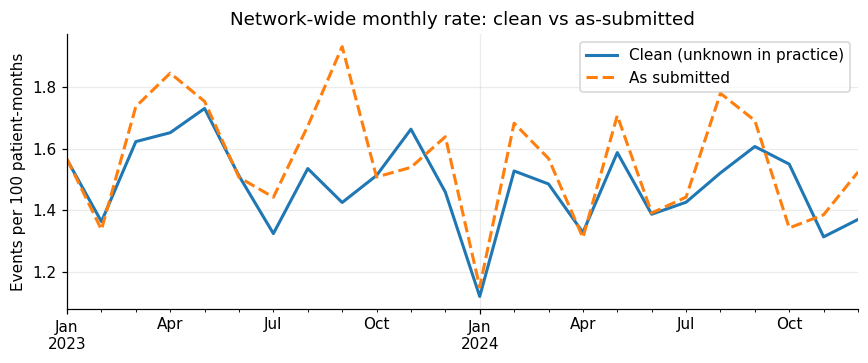

In [5]:
# Quick look: how much do the planted errors distort the monthly picture?
def monthly_rate(d, e):
    pm = d.groupby("month")["patients_total"].sum()
    return (e.groupby("month").size() / pm * 100)

fig, ax = plt.subplots(figsize=(8, 3.4))
monthly_rate(den_clean, ev_clean).plot(ax=ax, label="Clean (unknown in practice)", lw=2)
monthly_rate(den, ev).plot(ax=ax, label="As submitted", lw=2, ls="--")
ax.set_ylabel("Events per 100 patient-months"); ax.set_xlabel("")
ax.set_title("Network-wide monthly rate: clean vs as-submitted"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Rule-based validation
Ten documented rules in a single registry. The registry doubles as the **validation SOP**: each rule has an ID,
severity, plain-language description, the proposed system modification, and the suggested form-instruction edit.
Event-level rules (R1-R5) run on the line list; facility-month rules (R4*, R6-R9) run on denominators plus event counts.

*R4 is evaluated at both levels (per event, and aggregated to the facility-month).

In [6]:
RULES = pd.DataFrame([
    ("R1_date_outside_month", "event", 2, "Event date falls outside the reporting month it was entered under",
     "Hard stop at data entry when event date is outside the selected reporting month",
     "State that the event date, not the entry date, determines the reporting month."),
    ("R2_date_implausible", "event", 3, f"Event date before {MIN_PLAUSIBLE_YEAR} or after the submission date",
     "Block future dates and dates before facility enrollment",
     "Remind users that placeholder dates (for example 01/01/1900) must never be used."),
    ("R3_no_denominator", "event", 3, "Event reported for a facility-month with no submitted denominator",
     "Prevent saving events for a month until its denominator is submitted (or show a blocking alert)",
     "Add a step: complete the monthly denominator before entering events."),
    ("R4_zero_access_denominator", "event", 2, "Event access type has zero patients in that month's denominator",
     "Cross-field warning when event access type has a zero denominator count",
     "Clarify that denominator access-type counts must reflect each patient's access on the first two working days."),
    ("R5_duplicate_21d", "event", 2, f"Same patient and event type repeated within {DUP_WINDOW_DAYS} days",
     "Possible-duplicate alert that shows the earlier event at entry",
     "Add a worked example of the repeat-event window to the form instructions (confirm against current protocol)."),
    ("R6_missing_month", "facility-month", 2, "Enrolled facility has no denominator for a reporting month",
     "Automated missing-data report and reminder to facilities",
     "Add a monthly 'no events to report' attestation pathway."),
    ("R7_events_exceed_patients", "facility-month", 3, "Events for an access type exceed patients in that access category",
     "Numerator/denominator consistency check on submit",
     "Explain how event access type maps to denominator categories."),
    ("R8a_access_sum_mismatch", "facility-month", 2, "Total patients does not equal the sum of access-type counts",
     "Auto-calculate the total from access-type fields (read-only total)",
     "Clarify that the total is the sum of the access-type rows."),
    ("R8b_patient_count_outlier", "facility-month", 2, "Patient count is an outlier vs the facility's own history (robust |z| > 5)",
     "Soft warning when census differs sharply from prior months, with confirm button",
     "Add guidance for confirming unusually large or small census values."),
    ("R9_late_submission", "facility-month", 1, f"Submission more than {LATE_DAYS} days after month end",
     "Timeliness dashboard and automatic reminders at day 20 and day 28",
     "State the submission deadline prominently on the form."),
], columns=["rule_id", "level", "severity", "description", "proposed_modification", "form_instruction_edit"])
display(RULES[["rule_id", "level", "severity", "description"]])

,rule_id,level,severity,description
0,R1_date_outside_month,event,2,Event date falls outside the reporting month i...
1,R2_date_implausible,event,3,Event date before 2015 or after the submission...
2,R3_no_denominator,event,3,Event reported for a facility-month with no su...
3,R4_zero_access_denominator,event,2,Event access type has zero patients in that mo...
4,R5_duplicate_21d,event,2,Same patient and event type repeated within 21...
5,R6_missing_month,facility-month,2,Enrolled facility has no denominator for a rep...
6,R7_events_exceed_patients,facility-month,3,Events for an access type exceed patients in t...
7,R8a_access_sum_mismatch,facility-month,2,Total patients does not equal the sum of acces...
8,R8b_patient_count_outlier,facility-month,2,Patient count is an outlier vs the facility's ...
9,R9_late_submission,facility-month,1,Submission more than 30 days after month end


In [7]:
ACC_N = [f"n_{a}" for a in ACCESS]
EVENT_RULES = ["R1_date_outside_month", "R2_date_implausible", "R3_no_denominator", "R4_zero_access_denominator", "R5_duplicate_21d"]


def validate_events(ev, den):
    """Return the event line list with one boolean column per event-level rule."""
    e = ev.merge(den[["facility_id", "month"] + ACC_N], on=["facility_id", "month"], how="left", indicator=True)
    e["R3_no_denominator"] = e["_merge"].eq("left_only")
    a_idx = e["access_type"].map({a: i for i, a in enumerate(ACCESS)}).to_numpy()
    n_for_access = e[ACC_N].to_numpy(float)[np.arange(len(e)), a_idx]
    e["R4_zero_access_denominator"] = (~e["R3_no_denominator"]) & (np.nan_to_num(n_for_access, nan=1) == 0)
    e["R1_date_outside_month"] = e["event_date"].dt.to_period("M") != e["month"].dt.to_period("M")
    e["R2_date_implausible"] = (e["event_date"].dt.year < MIN_PLAUSIBLE_YEAR) | (e["event_date"] > e["report_date"])
    s = e.sort_values(["facility_id", "patient_id", "event_type", "event_date", "event_id"])
    same = (s[["facility_id", "patient_id", "event_type"]].shift().eq(s[["facility_id", "patient_id", "event_type"]]).all(axis=1))
    close = (s["event_date"] - s["event_date"].shift()).dt.days.between(0, DUP_WINDOW_DAYS)
    dup_ids = set(s.loc[same & close, "event_id"])
    e["R5_duplicate_21d"] = e["event_id"].isin(dup_ids)
    e["any_event_rule"] = e[EVENT_RULES].any(axis=1)
    return e.drop(columns=ACC_N + ["_merge"])


def validate_facility_months(den, ev_flags, months, fac_ids):
    grid = pd.MultiIndex.from_product([fac_ids, [m.to_timestamp() for m in months]],
                                      names=["facility_id", "month"]).to_frame(index=False)
    d = grid.merge(den, on=["facility_id", "month"], how="left")
    d["R6_missing_month"] = d["patients_total"].isna()
    present = ~d["R6_missing_month"]

    cnt = ev_flags.pivot_table(index=["facility_id", "month"], columns="access_type", values="event_id",
                               aggfunc="count", fill_value=0).reindex(columns=ACCESS, fill_value=0)
    cnt.columns = [f"ev_{a}" for a in ACCESS]
    d = d.merge(cnt.reset_index(), on=["facility_id", "month"], how="left")
    ev_cols = [f"ev_{a}" for a in ACCESS]
    d[ev_cols] = d[ev_cols].fillna(0).astype(int)
    d["events_total"] = d[ev_cols].sum(axis=1)

    d["R4_any"] = d.merge(ev_flags.groupby(["facility_id", "month"])["R4_zero_access_denominator"].any().rename("x").reset_index(),
                          on=["facility_id", "month"], how="left")["x"].fillna(False).astype(bool).to_numpy()
    d["R7_events_exceed_patients"] = present & (d[ev_cols].to_numpy() > d[ACC_N].fillna(0).to_numpy()).any(axis=1)
    d["R8a_access_sum_mismatch"] = present & (d["patients_total"] != d[ACC_N].sum(axis=1))
    lp = np.log(d["patients_total"].clip(lower=1))
    dev = lp - lp.groupby(d["facility_id"]).transform("median")
    mad = dev.abs().groupby(d["facility_id"]).transform("median")
    d["log_pat_dev"] = dev
    d["robust_z_patients"] = dev / np.maximum(1.4826 * mad, 0.03)       # floor avoids dividing by ~0
    d["R8b_patient_count_outlier"] = present & (d["robust_z_patients"].abs() > 5)
    d["delay_days"] = (d["report_date"] - (d["month"] + pd.offsets.MonthEnd(0))).dt.days
    d["R9_late_submission"] = present & (d["delay_days"] > LATE_DAYS)
    d["rule_fm_count"] = d[["R4_any", "R7_events_exceed_patients", "R8a_access_sum_mismatch",
                            "R8b_patient_count_outlier", "R9_late_submission"]].sum(axis=1)
    d["rule_fm_flag"] = d["rule_fm_count"] > 0
    return d


E = validate_events(ev, den)
D = validate_facility_months(den, E, MONTHS, fac.facility_id.tolist())

rule_cols_fm = ["R6_missing_month", "R7_events_exceed_patients", "R8a_access_sum_mismatch", "R8b_patient_count_outlier", "R9_late_submission"]
summary_rows = []
for r in EVENT_RULES:
    summary_rows.append((r, E[r].sum(), E[r].mean() * 100, E.loc[E[r], "facility_id"].nunique()))
for r in rule_cols_fm:
    base = len(D) if r == "R6_missing_month" else int((~D.R6_missing_month).sum())
    summary_rows.append((r, D[r].sum(), D[r].sum() / base * 100, D.loc[D[r], "facility_id"].nunique()))
rule_summary = pd.DataFrame(summary_rows, columns=["rule_id", "records_flagged", "pct_of_records", "facilities_affected"])
rule_summary["pct_of_records"] = rule_summary["pct_of_records"].round(2)
display(rule_summary)

,rule_id,records_flagged,pct_of_records,facilities_affected
0,R1_date_outside_month,82,1.88,61
1,R2_date_implausible,49,1.12,38
2,R3_no_denominator,89,2.04,42
3,R4_zero_access_denominator,74,1.70,55
4,R5_duplicate_21d,75,1.72,54
5,R6_missing_month,82,2.14,65
6,R7_events_exceed_patients,71,1.89,60
7,R8a_access_sum_mismatch,63,1.68,50
8,R8b_patient_count_outlier,76,2.02,59
9,R9_late_submission,129,3.43,93


### 4.1 How well do the rules work? (using ground truth)
**Event-level:** recall of each planted error by its target rule and by any rule, plus false alarms on clean events.
Note the honest result for `access_swapped`: R4 only fires when the swapped access type happens to have zero patients
that month, so it misses many swaps. A fuller consistency rule (for example, patient-level access history) would be a
concrete modification recommendation.

In [8]:
EV = E.merge(truth_ev, on="event_id", how="left")
targets = {"date_outside_month": "R1_date_outside_month", "date_implausible": "R2_date_implausible",
           "duplicate": "R5_duplicate_21d", "access_swapped": "R4_zero_access_denominator",
           "den_zero_access": "R4_zero_access_denominator", "no_denominator": "R3_no_denominator"}
rows = []
for lab, rule in targets.items():
    m = EV.err_event.str.contains(lab, regex=False)
    rows.append({"injected_error": lab, "n_injected": int(m.sum()), "target_rule": rule,
                 "recall_target_rule": round(EV.loc[m, rule].mean(), 3),
                 "recall_any_rule": round(EV.loc[m, EVENT_RULES].any(axis=1).mean(), 3)})
m = EV.err_event.str.contains("inflated_valid", regex=False)
rows.append({"injected_error": "inflated_valid", "n_injected": int(m.sum()), "target_rule": "(none possible)",
             "recall_target_rule": np.nan, "recall_any_rule": round(EV.loc[m, EVENT_RULES].any(axis=1).mean(), 3)})
display(pd.DataFrame(rows))

clean_ev = EV.err_event.eq("")
print(f"Clean events: {int(clean_ev.sum()):,} | flagged by any event rule (false alarms): {int(EV.loc[clean_ev, 'any_event_rule'].sum())}")

# Event-level precision per rule against ANY injected problem
prec = {r: round(1 - (EV.loc[EV[r], "err_event"] == "").mean(), 3) if EV[r].any() else np.nan for r in EVENT_RULES}
print("Precision per event rule (flag is a true planted problem):", prec)

,injected_error,n_injected,target_rule,recall_target_rule,recall_any_rule
0,date_outside_month,56,R1_date_outside_month,1.000,1.000
1,date_implausible,26,R2_date_implausible,1.000,1.000
2,duplicate,75,R5_duplicate_21d,1.000,1.000
3,access_swapped,56,R4_zero_access_denominator,0.143,0.143
4,den_zero_access,68,R4_zero_access_denominator,0.971,1.000
5,no_denominator,89,R3_no_denominator,1.000,1.000
6,inflated_valid,511,(none possible),NaN,0.029


Clean events: 3,507 | flagged by any event rule (false alarms): 0
Precision per event rule (flag is a true planted problem): {'R1_date_outside_month': 1.0, 'R2_date_implausible': 1.0, 'R3_no_denominator': 1.0, 'R4_zero_access_denominator': 1.0, 'R5_duplicate_21d': 1.0}


## 5. Statistical anomaly detection
Rules catch what we can *specify*. Statistics catch what looks *unusual*.

1. **Robust z-score** (median/MAD) of the patient count within each facility (already computed as `robust_z_patients`).
2. **Poisson plausibility** of each facility-month's event count given its denominators and network-wide pooled rates
   by access type.
3. **Funnel plot** of facility standardized ratios (observed/expected over 24 months) with Poisson control limits,
   then limits widened for **overdispersion** (Spiegelhalter-style square-root approximation). Without that adjustment, a funnel plot of
   real surveillance data flags far too many facilities.

In [9]:
present_mask = ~D.R6_missing_month
pooled = {a: D.loc[present_mask, f"ev_{a}"].sum() / D.loc[present_mask, f"n_{a}"].sum() for a in ACCESS}
print("Pooled (as-submitted) events per 100 patient-months by access:",
      {a: round(v * 100, 2) for a, v in pooled.items()})

D["expected_events"] = sum(D[f"n_{a}"].fillna(0) * pooled[a] for a in ACCESS)
D["sir_fm"] = np.where(D.expected_events > 0, D.events_total / D.expected_events, np.nan)
D["pois_nlogp"] = np.where(present_mask & (D.expected_events > 0),
                           -np.log10(np.clip(stats.poisson.sf(D.events_total - 1, D.expected_events.clip(lower=1e-9)), 1e-300, 1)), 0.0)
print("Facility-months with Poisson upper-tail p < 0.001:", int((D.pois_nlogp > 3).sum()))

Pooled (as-submitted) events per 100 patient-months by access: {'AVF': 0.75, 'AVG': 1.57, 'CVC_tunneled': 3.62, 'CVC_nontunneled': 7.31, 'Other': 1.27}
Facility-months with Poisson upper-tail p < 0.001: 63


Estimated overdispersion factor phi = 2.41  (1.0 would mean pure Poisson noise)


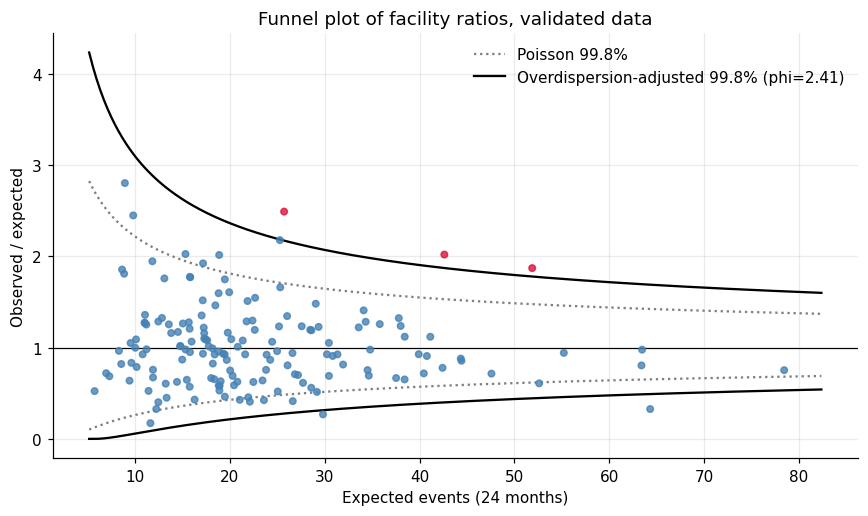

Facilities above the 99.8% limit: Poisson-only 9, overdispersion-adjusted 3 of 160


In [10]:
# Funnel plot on VALIDATED data: drop events failing hard rules and facility-months failing facility-month rules
bad_keys = set(zip(D.loc[D.rule_fm_flag | D.R6_missing_month, "facility_id"], D.loc[D.rule_fm_flag | D.R6_missing_month, "month"]))
ev_ok = E[~E.any_event_rule & ~pd.Series(list(zip(E.facility_id, E.month))).isin(bad_keys).to_numpy()]
d_ok = D[present_mask & ~D.rule_fm_flag]

pooled_v = {a: ev_ok[ev_ok.access_type == a].shape[0] / d_ok[f"n_{a}"].sum() for a in ACCESS}
d_ok = d_ok.assign(expected_v=sum(d_ok[f"n_{a}"] * pooled_v[a] for a in ACCESS))
funnel = (d_ok.groupby("facility_id")["expected_v"].sum().rename("E").to_frame()
          .join(ev_ok.groupby("facility_id").size().rename("O")).fillna({"O": 0}))
funnel["SIR"] = funnel.O / funnel.E

z = ((funnel.O - funnel.E) / np.sqrt(funnel.E)).to_numpy()
lo, hi = np.percentile(z, [10, 90])
phi = max(1.0, float(np.mean(np.clip(z, lo, hi) ** 2)))     # winsorised Pearson dispersion
print(f"Estimated overdispersion factor phi = {phi:.2f}  (1.0 would mean pure Poisson noise)")

grid_E = np.linspace(max(funnel.E.min() * 0.9, 0.5), funnel.E.max() * 1.05, 400)
Z998 = stats.norm.ppf(1 - 0.002 / 2)       # two-sided 99.8% limits

def funnel_limits(E, z, disp=1.0):
    """Square-root approximation for Poisson ratios: sqrt(O/E) ~ N(1, 1/(4E)) (Spiegelhalter 2005);
    overdispersion widens the spread by sqrt(phi). Smooth and accurate except for very small E."""
    half = z * np.sqrt(disp) / (2 * np.sqrt(E))
    return np.clip(1 - half, 0, None) ** 2, (1 + half) ** 2

lo_p, up_p = funnel_limits(grid_E, Z998)
lo_a, up_a = funnel_limits(grid_E, Z998, phi)
funnel["outside_pois_998"] = funnel.SIR > funnel_limits(funnel.E.to_numpy(), Z998)[1]
funnel["outside_adj_998"] = funnel.SIR > funnel_limits(funnel.E.to_numpy(), Z998, phi)[1]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(funnel.E, funnel.SIR, s=18, c=np.where(funnel.outside_adj_998, "crimson", "steelblue"), alpha=0.8, zorder=3)
ax.plot(grid_E, up_p, color="gray", ls=":", label="Poisson 99.8%")
ax.plot(grid_E, lo_p, color="gray", ls=":")
ax.plot(grid_E, up_a, color="black", label=f"Overdispersion-adjusted 99.8% (phi={phi:.2f})")
ax.plot(grid_E, lo_a, color="black")
ax.axhline(1, color="k", lw=0.8)
ax.set_xlabel("Expected events (24 months)"); ax.set_ylabel("Observed / expected")
ax.set_title("Funnel plot of facility ratios, validated data"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"Facilities above the 99.8% limit: Poisson-only {int(funnel.outside_pois_998.sum())}, overdispersion-adjusted {int(funnel.outside_adj_998.sum())} of {len(funnel)}")

## 6. Neural-net anomaly detection: denoising autoencoder vs Isolation Forest
**Idea:** train an autoencoder to reconstruct normal facility-month feature vectors, with Gaussian noise added to the
input during training (denoising). Submissions that reconstruct poorly are unusual. It is unsupervised: labels are never
used for training, only for scoring afterwards. Features are deliberately **facility-normalized** (deviation from the
facility's own typical access mix and census) and do not include rule outputs, so the models are tested independently
of the rules.

In [11]:
share = D[ACC_N].div(D[ACC_N].sum(axis=1).replace(0, np.nan), axis=0)
share.columns = [f"share_{a}" for a in ACCESS]
share_dev = share - share.groupby(D.facility_id).transform("median")
share_dev.columns = [f"share_dev_{a}" for a in ACCESS]

FM = pd.concat([D[["facility_id", "month", "patients_total", "log_pat_dev", "delay_days", "events_total", "pois_nlogp",
                   "rule_fm_flag", "rule_fm_count"]], share_dev], axis=1)
FM["log_patients"] = np.log(D.patients_total.clip(lower=1))
FM["sum_gap"] = (D.patients_total - D[ACC_N].sum(axis=1)) / D.patients_total.clip(lower=1)
FM["log1p_events"] = np.log1p(D.events_total)
FM["max_ev_ratio"] = (D[[f"ev_{a}" for a in ACCESS]].to_numpy() / (D[ACC_N].fillna(0).to_numpy() + 1)).max(axis=1)
FM = FM[present_mask.to_numpy()].reset_index(drop=True)
FM = FM.merge(truth_fm[["facility_id", "month", "patient_typo", "sum_mismatch", "zero_access", "late", "inflation", "has_fm_error"]],
              on=["facility_id", "month"], how="left")

feat_cols = (["log_patients", "log_pat_dev", "sum_gap", "log1p_events", "max_ev_ratio", "delay_days"] + list(share_dev.columns))
X_raw = FM[feat_cols].fillna(0).to_numpy(float)
X = np.clip(RobustScaler().fit_transform(X_raw), -4, 4).astype(np.float32)
y = FM["has_fm_error"].to_numpy(bool)
print(f"{len(FM):,} scored facility-months | {y.sum()} with an injected facility-month error ({y.mean():.1%}) | {len(feat_cols)} features")

3,758 scored facility-months | 391 with an injected facility-month error (10.4%) | 11 features


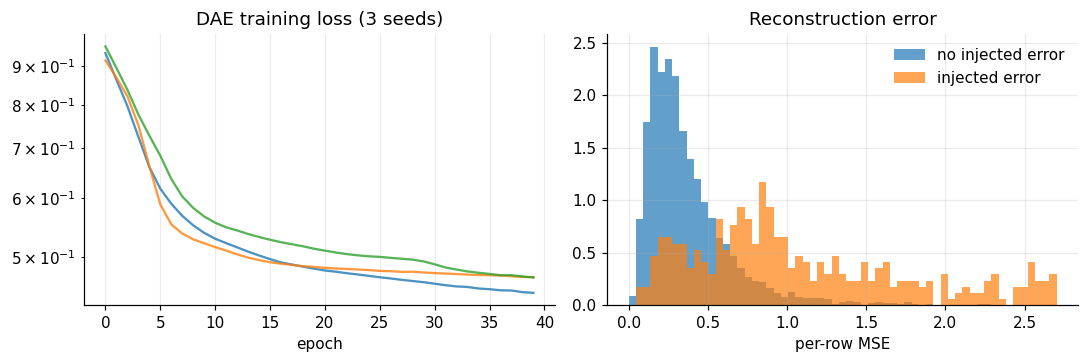

In [12]:
class DAE(nn.Module):
    """Small denoising autoencoder. A narrow linear bottleneck is deliberate: a wider one memorizes rare
    outliers (for example, late submissions) and then reconstructs them well, hiding exactly what we want to find."""
    def __init__(self, d_in, h=16, z=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d_in, h), nn.ReLU(), nn.Linear(h, z))
        self.dec = nn.Sequential(nn.Linear(z, h), nn.ReLU(), nn.Linear(h, d_in))
    def forward(self, x):
        return self.dec(self.enc(x))


def train_dae(X, seed, epochs=40, noise=0.15, lr=2e-3, bs=256):
    torch.manual_seed(seed)
    Xt = torch.from_numpy(X)
    model = DAE(X.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    losses = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xt)); tot = 0.0
        for i in range(0, len(Xt), bs):
            xb = Xt[perm[i:i + bs]]
            loss = nn.functional.mse_loss(model(xb + noise * torch.randn_like(xb)), xb)   # denoising objective
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(xb)
        losses.append(tot / len(Xt))
    return model, losses


def dae_score(model, X):
    with torch.no_grad():
        xt = torch.from_numpy(X)
        return ((model(xt) - xt) ** 2).mean(dim=1).numpy()


models, all_losses = [], []
for s in range(3):                                   # small ensemble of 3 seeds for stability
    m_, l_ = train_dae(X, seed=SEED + s)
    models.append(m_); all_losses.append(l_)
dae = np.mean([dae_score(m_, X) for m_ in models], axis=0)

iso = IsolationForest(n_estimators=300, random_state=SEED).fit(X)
iso_score = -iso.score_samples(X)
max_rz = np.abs(X).max(axis=1)                       # multi-feature robust z baseline

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for l_ in all_losses: ax[0].plot(l_, alpha=0.8)
ax[0].set_title("DAE training loss (3 seeds)"); ax[0].set_xlabel("epoch"); ax[0].set_yscale("log")
bins = np.linspace(0, np.percentile(dae, 99.5), 60)
ax[1].hist(dae[~y], bins=bins, alpha=0.7, density=True, label="no injected error")
ax[1].hist(dae[y], bins=bins, alpha=0.7, density=True, label="injected error")
ax[1].set_title("Reconstruction error"); ax[1].set_xlabel("per-row MSE"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

### 6.1 Head-to-head comparison
All methods are scored against the planted facility-month errors (`patient_typo`, `sum_mismatch`, `zero_access`, `late`,
`inflation`). Precision and recall are reported at a fixed review budget equal to the number of true errors, which is the
realistic question for an analyst: *if I can review K submissions, how many real problems do I find?*

**Reading the results honestly:** the rules were written for these specific error types, so they should do very well on
them. The statistical and ML methods matter because they require no pre-specified rule, and because some problems (here,
over-reporting) cannot be written as a rule at all.

In [13]:
def topk_metrics(y, s, k):
    idx = np.argsort(-s, kind="stable")[:k]
    tp = y[idx].sum()
    return tp / k, tp / y.sum()

scores = {"Rules (count of rules fired)": FM.rule_fm_count.to_numpy(float),
          "Poisson plausibility": FM.pois_nlogp.to_numpy(float),
          "Max robust z (features)": max_rz,
          "Isolation Forest": iso_score,
          "Denoising autoencoder": dae}
K = int(y.sum())
rows = []
for name, s in scores.items():
    p, r = topk_metrics(y, s, K)
    rows.append({"method": name, "AUROC": round(roc_auc_score(y, s), 3), "AUPRC": round(average_precision_score(y, s), 3),
                 f"precision@K={K}": round(p, 3), f"recall@K={K}": round(r, 3)})

# Hybrid review list: any rule fires, OR Poisson p < 0.001, OR the autoencoder's top 5%
dae_top = dae >= np.percentile(dae, 95)
hybrid = FM.rule_fm_flag.to_numpy() | (FM.pois_nlogp.to_numpy() > 3) | dae_top
rows.append({"method": "Hybrid: rules OR Poisson OR DAE top 5%", "AUROC": np.nan, "AUPRC": np.nan,
             f"precision@K={K}": round(y[hybrid].mean(), 3), f"recall@K={K}": round(y[hybrid].sum() / y.sum(), 3)})
comparison = pd.DataFrame(rows)
print(f"Prevalence of injected facility-month errors: {y.mean():.3f} (AUPRC of a random scorer)")
display(comparison)
print(f"Hybrid row: precision and recall of the combined flag set, which flags {int(hybrid.sum())} rows (not K={K}), so compare it on workload as well.")

Prevalence of injected facility-month errors: 0.104 (AUPRC of a random scorer)


,method,AUROC,AUPRC,precision@K=391,recall@K=391
0,Rules (count of rules fired),0.885,0.762,0.785,0.785
1,Poisson plausibility,0.646,0.335,0.315,0.315
2,Max robust z (features),0.885,0.454,0.522,0.522
3,Isolation Forest,0.939,0.700,0.637,0.637
4,Denoising autoencoder,0.855,0.577,0.542,0.542
5,Hybrid: rules OR Poisson OR DAE top 5%,NaN,NaN,0.834,0.887


Hybrid row: precision and recall of the combined flag set, which flags 416 rows (not K=391), so compare it on workload as well.


,n_injected,Rules,Poisson (p<0.001),Isolation Forest (top K),DAE (top K),Hybrid (rules OR Poisson OR DAE top 5%)
patient_typo,56,1.000,0.000,0.982,1.000,1.000
sum_mismatch,63,1.000,0.000,0.889,0.746,1.000
zero_access,55,1.000,0.055,0.964,0.582,1.000
late,129,1.000,0.023,0.395,0.612,1.000
inflation,101,0.129,0.515,0.465,0.089,0.564


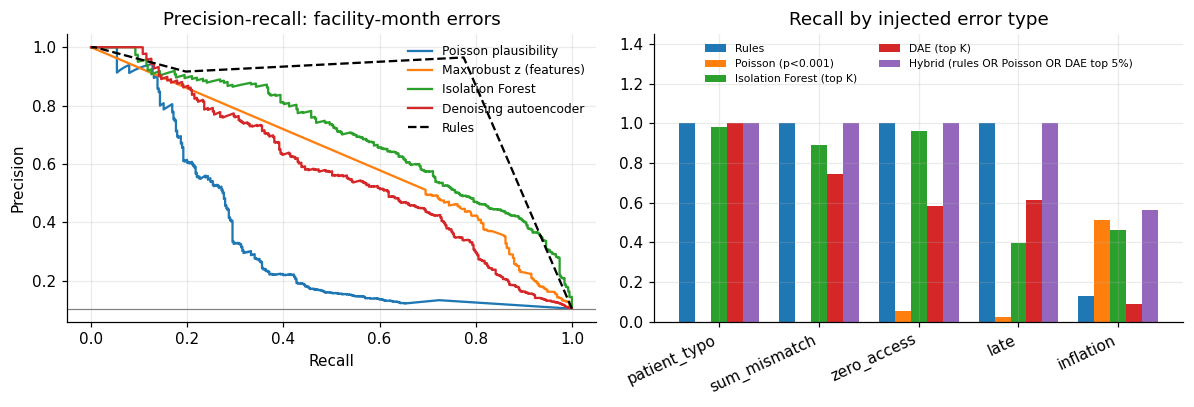

In [14]:
# Recall by error type: where does each method win or lose?
err_types = ["patient_typo", "sum_mismatch", "zero_access", "late", "inflation"]
flag_sets = {"Rules": FM.rule_fm_flag.to_numpy(),
             "Poisson (p<0.001)": (FM.pois_nlogp > 3).to_numpy(),
             "Isolation Forest (top K)": np.isin(np.arange(len(y)), np.argsort(-iso_score)[:K]),
             "DAE (top K)": np.isin(np.arange(len(y)), np.argsort(-dae)[:K]),
             "Hybrid (rules OR Poisson OR DAE top 5%)": hybrid}
by_type = pd.DataFrame({name: {t: flag[FM[t].to_numpy(bool)].mean() for t in err_types}
                        for name, flag in flag_sets.items()}).round(3)
by_type.insert(0, "n_injected", [int(FM[t].sum()) for t in err_types])
display(by_type)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, s in scores.items():
    if name.startswith("Rules"):
        continue
    pr, rc, _ = precision_recall_curve(y, s); ax[0].plot(rc, pr, label=name)
pr, rc, _ = precision_recall_curve(y, scores["Rules (count of rules fired)"]); ax[0].plot(rc, pr, "k--", label="Rules")
ax[0].axhline(y.mean(), color="gray", lw=0.8); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision")
ax[0].set_title("Precision-recall: facility-month errors"); ax[0].legend(frameon=False, fontsize=8)
by_type.drop(columns="n_injected").plot.bar(ax=ax[1], width=0.8)
ax[1].set_title("Recall by injected error type"); ax[1].set_ylim(0, 1.45); ax[1].legend(frameon=False, fontsize=7, ncol=2, loc="upper center")
ax[1].set_xticklabels(err_types, rotation=25, ha="right")
plt.tight_layout(); plt.show()

## 7. Facility data quality scorecard
A single 0-100 score per facility built from five documented components. The weights and tier cut-offs are an
**analyst proposal** and would be reviewed with the surveillance team before use. Tiers translate directly into outreach
priority.

| Component | Weight | Definition |
|---|---|---|
| Completeness | 25% | Share of months with a submitted denominator |
| Event validity | 25% | Share of events passing R1-R5 |
| Denominator consistency | 25% | Share of submitted months passing R4, R7, R8a, R8b |
| Timeliness | 15% | Share of submissions within 30 days |
| Statistical plausibility | 10% | Share of months not flagged by Poisson (p<0.001) or DAE top 5% |

tier
C: targeted outreach     20
B: watch list            70
A: routine monitoring    70


,facility_id,state,network,ownership,urban_rural,mean_census,completeness,timeliness,den_consistency,plausibility,event_validity,dq_score,tier
0,FAC0085,PA,NW-01,Large_chain,Rural,53,95.8,95.7,78.3,87.0,81.0,86.8,C: targeted outreach
1,FAC0152,TX,NW-03,Large_chain,Urban,109,87.5,81.0,90.5,90.5,86.8,87.4,C: targeted outreach
2,FAC0025,IL,NW-02,Nonprofit,Rural,23,95.8,100.0,95.7,91.3,62.5,87.6,C: targeted outreach
3,FAC0039,TX,NW-03,Large_chain,Rural,31,95.8,95.7,91.3,91.3,70.0,87.8,C: targeted outreach
4,FAC0134,OH,NW-06,Nonprofit,Urban,135,87.5,90.5,90.5,81.0,88.1,88.2,C: targeted outreach
5,FAC0064,MI,NW-04,Large_chain,Urban,77,95.8,95.7,82.6,82.6,83.9,88.2,C: targeted outreach
6,FAC0024,MI,NW-04,Independent,Urban,36,100.0,95.8,87.5,87.5,73.7,88.4,C: targeted outreach
7,FAC0091,NY,NW-05,Large_chain,Urban,105,91.7,95.5,95.5,95.5,74.4,89.2,C: targeted outreach
8,FAC0119,TX,NW-03,Large_chain,Urban,17,100.0,95.8,87.5,66.7,85.7,89.3,C: targeted outreach
9,FAC0062,IL,NW-02,Large_chain,Urban,56,95.8,95.7,100.0,100.0,65.2,89.6,C: targeted outreach


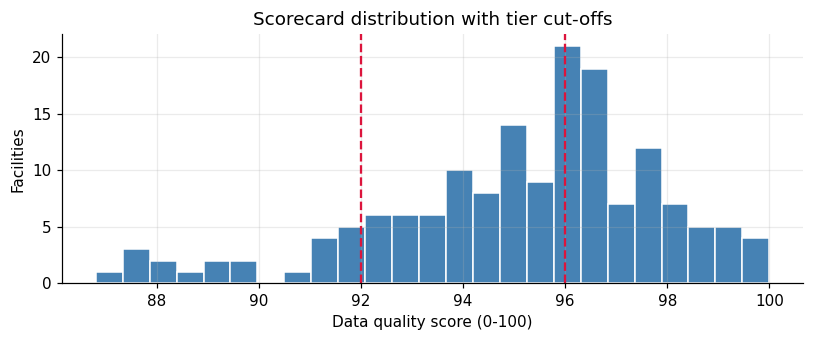

In [15]:
TIER_C, TIER_B = 92, 96          # proposed cut-offs (analyst judgment; calibrate with the surveillance team)
D_p = D[present_mask].copy()
dae_by_key = pd.DataFrame({"facility_id": FM.facility_id, "month": FM.month, "dae_top5": dae_top})
D_p = D_p.merge(dae_by_key, on=["facility_id", "month"], how="left")
D_p["den_inconsistent"] = D_p[["R4_any", "R7_events_exceed_patients", "R8a_access_sum_mismatch", "R8b_patient_count_outlier"]].any(axis=1)
D_p["stat_flag"] = (D_p.pois_nlogp > 3) | D_p.dae_top5.fillna(False)

sc = pd.DataFrame({
    "completeness": 1 - D.groupby("facility_id")["R6_missing_month"].mean(),
    "timeliness": 1 - D_p.groupby("facility_id")["R9_late_submission"].mean(),
    "den_consistency": 1 - D_p.groupby("facility_id")["den_inconsistent"].mean(),
    "plausibility": 1 - D_p.groupby("facility_id")["stat_flag"].mean(),
})
ev_valid = 1 - E.groupby("facility_id")["any_event_rule"].mean()
sc["event_validity"] = ev_valid.reindex(sc.index).fillna(1.0)
sc["dq_score"] = 100 * (0.25 * sc.completeness + 0.25 * sc.event_validity + 0.25 * sc.den_consistency
                        + 0.15 * sc.timeliness + 0.10 * sc.plausibility)
sc["tier"] = pd.cut(sc.dq_score, [-np.inf, TIER_C, TIER_B, np.inf],
                    labels=["C: targeted outreach", "B: watch list", "A: routine monitoring"])
scorecard = fac[["facility_id", "state", "network", "ownership", "urban_rural", "mean_census"]].merge(
    sc.reset_index(), on="facility_id").sort_values("dq_score").reset_index(drop=True)
scorecard[["completeness", "event_validity", "den_consistency", "timeliness", "plausibility"]] = \
    (scorecard[["completeness", "event_validity", "den_consistency", "timeliness", "plausibility"]] * 100).round(1)
scorecard["dq_score"] = scorecard.dq_score.round(1)

print(scorecard.tier.value_counts().sort_index().to_string())
display(scorecard.head(10))
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(scorecard.dq_score, bins=25, color="steelblue", edgecolor="white")
for cut in (TIER_C, TIER_B): ax.axvline(cut, color="crimson", ls="--")
ax.set_xlabel("Data quality score (0-100)"); ax.set_ylabel("Facilities"); ax.set_title("Scorecard distribution with tier cut-offs")
plt.tight_layout(); plt.show()

## 8. System modification tracking log and form-instruction edits
Each rule's observed impact becomes a trackable change request. Priority is `severity x log(1 + records affected)`, ranked:
top 3 = High, next 4 = Medium, rest = Low. This is the "analyze system function, develop and track modifications"
duty in miniature.

In [16]:
mod = RULES.merge(rule_summary, on="rule_id")
mod["priority_score"] = (mod.severity * np.log1p(mod.records_flagged)).round(2)
mod = mod.sort_values("priority_score", ascending=False).reset_index(drop=True)
mod["priority"] = np.where(mod.index < 3, "High", np.where(mod.index < 7, "Medium", "Low"))
mod.insert(0, "mod_id", [f"SM-{i+1:03d}" for i in range(len(mod))])
mod_log = mod.assign(
    issue=mod.description, date_logged=pd.Timestamp.today().date(), status="Proposed",
    proposed_owner="Surveillance Branch + NHSN IT (proposed)",
)[["mod_id", "date_logged", "rule_id", "issue", "records_flagged", "pct_of_records", "facilities_affected",
   "severity", "priority_score", "priority", "proposed_modification", "status", "proposed_owner"]]
display(mod_log)

form_edits = mod[["rule_id", "priority", "form_instruction_edit"]].rename(
    columns={"form_instruction_edit": "recommended_edit_to_form_instructions"})
display(form_edits)

,mod_id,date_logged,rule_id,issue,records_flagged,pct_of_records,facilities_affected,severity,priority_score,priority,proposed_modification,status,proposed_owner
0,SM-001,2026-10-14,R3_no_denominator,Event reported for a facility-month with no su...,89,2.04,42,3,13.50,High,Prevent saving events for a month until its de...,Proposed,Surveillance Branch + NHSN IT (proposed)
1,SM-002,2026-10-14,R7_events_exceed_patients,Events for an access type exceed patients in t...,71,1.89,60,3,12.83,High,Numerator/denominator consistency check on submit,Proposed,Surveillance Branch + NHSN IT (proposed)
2,SM-003,2026-10-14,R2_date_implausible,Event date before 2015 or after the submission...,49,1.12,38,3,11.74,High,Block future dates and dates before facility e...,Proposed,Surveillance Branch + NHSN IT (proposed)
3,SM-004,2026-10-14,R1_date_outside_month,Event date falls outside the reporting month i...,82,1.88,61,2,8.84,Medium,Hard stop at data entry when event date is out...,Proposed,Surveillance Branch + NHSN IT (proposed)
4,SM-005,2026-10-14,R6_missing_month,Enrolled facility has no denominator for a rep...,82,2.14,65,2,8.84,Medium,Automated missing-data report and reminder to ...,Proposed,Surveillance Branch + NHSN IT (proposed)
5,SM-006,2026-10-14,R8b_patient_count_outlier,Patient count is an outlier vs the facility's ...,76,2.02,59,2,8.69,Medium,Soft warning when census differs sharply from ...,Proposed,Surveillance Branch + NHSN IT (proposed)
6,SM-007,2026-10-14,R5_duplicate_21d,Same patient and event type repeated within 21...,75,1.72,54,2,8.66,Medium,Possible-duplicate alert that shows the earlie...,Proposed,Surveillance Branch + NHSN IT (proposed)
7,SM-008,2026-10-14,R4_zero_access_denominator,Event access type has zero patients in that mo...,74,1.70,55,2,8.63,Low,Cross-field warning when event access type has...,Proposed,Surveillance Branch + NHSN IT (proposed)
8,SM-009,2026-10-14,R8a_access_sum_mismatch,Total patients does not equal the sum of acces...,63,1.68,50,2,8.32,Low,Auto-calculate the total from access-type fiel...,Proposed,Surveillance Branch + NHSN IT (proposed)
9,SM-010,2026-10-14,R9_late_submission,Submission more than 30 days after month end,129,3.43,93,1,4.87,Low,Timeliness dashboard and automatic reminders a...,Proposed,Surveillance Branch + NHSN IT (proposed)


,rule_id,priority,recommended_edit_to_form_instructions
0,R3_no_denominator,High,Add a step: complete the monthly denominator b...
1,R7_events_exceed_patients,High,Explain how event access type maps to denomina...
2,R2_date_implausible,High,Remind users that placeholder dates (for examp...
3,R1_date_outside_month,Medium,"State that the event date, not the entry date,..."
4,R6_missing_month,Medium,Add a monthly 'no events to report' attestatio...
5,R8b_patient_count_outlier,Medium,Add guidance for confirming unusually large or...
6,R5_duplicate_21d,Medium,Add a worked example of the repeat-event windo...
7,R4_zero_access_denominator,Low,Clarify that denominator access-type counts mu...
8,R8a_access_sum_mismatch,Low,Clarify that the total is the sum of the acces...
9,R9_late_submission,Low,State the submission deadline prominently on t...


## 9. Data dictionary and exports
Government-contractor style deliverables: every table documented, outputs in CSV and a multi-sheet Excel workbook
(the posting names Excel and Access, so analysis outputs should open cleanly there).

In [17]:
dd = pd.DataFrame([
    ("facilities", "facility_id", "string", "Synthetic facility identifier (not a real CCN)", "FAC0001-FAC0160"),
    ("facilities", "state / network", "string", "Synthetic state and synthetic network code", "NW-01..NW-06"),
    ("facilities", "ownership / urban_rural", "string", "Facility characteristics used for later fairness checks", "Large_chain|Nonprofit|Independent; Urban|Rural"),
    ("facilities", "mean_census", "int", "Average patients under care", "15-250"),
    ("facilities", "log_effect, in_collaborative", "float, bool", "GROUND TRUTH only: latent risk and simulated collaborative membership", "evaluation only"),
    ("denominator", "facility_id, month", "string, date", "Reporting facility and first day of reporting month", ""),
    ("denominator", "report_date", "date", "Submission date for the month's data", ""),
    ("denominator", "patients_total", "int", "Total patients (patient-months for the month)", ">=1"),
    ("denominator", "n_AVF ... n_Other", "int", "Patients by vascular access type; should sum to patients_total", ">=0"),
    ("events", "event_id", "string", "Event identifier (EVD = injected duplicate, EVX = injected over-report; remove in real data)", ""),
    ("events", "patient_id", "string", "Synthetic patient identifier within facility", ""),
    ("events", "event_type", "string", "Surveillance event category", "|".join(EVENT_TYPES)),
    ("events", "access_type", "string", "Vascular access at time of event", "|".join(ACCESS)),
    ("events", "event_date, report_date", "date", "Date of event; submission date of the month's data", ""),
    ("truth_events", "err_event", "string", "GROUND TRUTH: injected event-level error labels, '|' separated", "evaluation only"),
    ("truth_facility_months", "missing ... inflation", "bool", "GROUND TRUTH: injected facility-month errors", "evaluation only"),
    ("scorecard", "dq_score, tier", "float, string", "Composite 0-100 data quality score and outreach tier", "A|B|C"),
    ("scorecard", "completeness ... plausibility", "float", "Component scores, percent", "0-100"),
], columns=["table", "column", "type", "description", "allowed_values_or_note"])
display(dd)

,table,column,type,description,allowed_values_or_note
0,facilities,facility_id,string,Synthetic facility identifier (not a real CCN),FAC0001-FAC0160
1,facilities,state / network,string,Synthetic state and synthetic network code,NW-01..NW-06
2,facilities,ownership / urban_rural,string,Facility characteristics used for later fairne...,Large_chain|Nonprofit|Independent; Urban|Rural
3,facilities,mean_census,int,Average patients under care,15-250
4,facilities,"log_effect, in_collaborative","float, bool",GROUND TRUTH only: latent risk and simulated c...,evaluation only
5,denominator,"facility_id, month","string, date",Reporting facility and first day of reporting ...,
6,denominator,report_date,date,Submission date for the month's data,
7,denominator,patients_total,int,Total patients (patient-months for the month),>=1
8,denominator,n_AVF ... n_Other,int,Patients by vascular access type; should sum t...,>=0
9,events,event_id,string,"Event identifier (EVD = injected duplicate, EV...",


In [18]:
fac.to_csv(f"{OUT}/facilities.csv", index=False)
den.to_csv(f"{OUT}/denominator_submitted.csv", index=False)
ev.to_csv(f"{OUT}/events_submitted.csv", index=False)
truth_ev.to_csv(f"{OUT}/truth_events.csv", index=False)
truth_fm.to_csv(f"{OUT}/truth_facility_months.csv", index=False)
dd.to_csv(f"{OUT}/data_dictionary.csv", index=False)
scorecard.to_csv(f"{OUT}/facility_dq_scorecard.csv", index=False)
mod_log.to_csv(f"{OUT}/system_modification_log.csv", index=False)

with pd.ExcelWriter(f"{OUT}/dq_report.xlsx", engine="openpyxl") as xw:
    scorecard.to_excel(xw, sheet_name="Facility scorecard", index=False)
    rule_summary.to_excel(xw, sheet_name="Rule summary", index=False)
    comparison.to_excel(xw, sheet_name="Method comparison", index=False)
    by_type.reset_index(names="error_type").to_excel(xw, sheet_name="Recall by error type", index=False)
    mod_log.to_excel(xw, sheet_name="Modification log", index=False)
    form_edits.to_excel(xw, sheet_name="Form instruction edits", index=False)
    dd.to_excel(xw, sheet_name="Data dictionary", index=False)
    for ws in xw.book.worksheets:
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = min(60, max(12, max(len(str(c.value or "")) for c in col[:50]) + 2))
        ws.freeze_panes = "A2"

shutil.make_archive("nhsn_dq_outputs", "zip", OUT)
print(sorted(os.listdir(OUT)))

try:                                                     # offers a download only when running in Colab
    from google.colab import files
    files.download("nhsn_dq_outputs.zip")
except Exception:
    print("Not in Colab (or download blocked). Files are in ./outputs and nhsn_dq_outputs.zip")

['data_dictionary.csv', 'denominator_submitted.csv', 'dq_report.xlsx', 'events_submitted.csv', 'facilities.csv', 'facility_dq_scorecard.csv', 'system_modification_log.csv', 'truth_events.csv', 'truth_facility_months.csv']
Not in Colab (or download blocked). Files are in ./outputs and nhsn_dq_outputs.zip


## 10. So what for public health?
- **Validation is measurable.** Because errors were planted, we can state what each check catches and misses, instead of
  asserting that a check "works".
- **Rules and statistics are complements.** Rules are precise and explainable for known error patterns. Statistical and ML
  methods find unspecified problems and are the only option for plausible-looking over-reporting. In practice the best
  workflow is a hybrid: automatic rules first, then a short statistical review list.
- **Do not over-trust a neural net.** Compare the autoencoder against Isolation Forest and the simple robust-z baseline in
  the tables above. Where a simpler method matches it, prefer the simpler, more explainable one.
- **Funnel plots need overdispersion adjustment.** A pure Poisson funnel over-flags facilities, which would waste outreach
  effort and unfairly label small or ordinary facilities as outliers.
- **Outputs map to actions:** the scorecard prioritizes who to contact, the modification log prioritizes what to fix in the
  system, and the form-instruction edits turn recurring user mistakes into clearer guidance.

## Limitations
- Entirely synthetic: real NHSN errors are more varied and correlated than those injected here.
- Rule definitions are illustrative and must be verified against the current NHSN protocol before use.
- The scorecard weights, tier cut-offs, and priority formula are proposals, not validated standards.
- The autoencoder was trained on data that includes the errors (as it would in practice); results depend on the injected error rate.
- Event rates are illustrative and not calibrated to national benchmarks.

## Next notebooks
`02` Negative binomial and Bayesian hierarchical rate models | `03` ITS, difference-in-differences, forecasting | `04` Outreach prioritization with
tabular NN and SHAP | `05` Inquiry triage, facility reports, training materials.